# 2. Сравнимость групп

Основная выборка - все ученики в файле, у каждого есть восстановленная группа. Вторичная - те, кто увидел условие
(`experienced`). Это похоже на триггерный анализ в онлайн-экспериментах. Он честный, только если момент срабатывания
одинаково отбирает учеников в обеих группах: тогда доля сработавших в C и E совпадает и ковариаты среди них сбалансированы.

Что проверяю в каждом эксперименте:
1. SRM на всей выборке. Ожидаемое соотношение групп в статьях не указано, поэтому беру 50/50 (допущение).
2. Симметрию триггера: доля увидевших условие в C и E, z-тест для долей. Если p < 0,05, триггерный анализ не делаю.
3. Баланс ковариат: стандартизованная разница средних (SMD) на всей выборке и среди увидевших условие.
4. Проверку видео: доля не видящих видео в C и E.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, false_discovery_control

from src import config, db, stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
con = db.connect()
rng = np.random.default_rng(config.SEED)

## SRM

Хи-квадрат согласия с ожидаемым делением 50/50. Эксперимент исключаю при p < 0,001: при 22 тестах порог 0,05
сам по себе дал бы около одного ложного срабатывания.

In [2]:
groups = db.run(con, "groups.sql", "group_sizes")
groups["share_c"] = groups.n_c / (groups.n_c + groups.n_e)
groups["srm_p"] = [stats.srm_pvalue(c, e) for c, e in zip(groups.n_c, groups.n_e)]
groups[["experiment_id", "n_c", "n_e", "share_c", "srm_p"]].round(4)

,experiment_id,n_c,n_e,share_c,srm_p
0,226210,607,578,0.5122,0.3995
1,237447,329,363,0.4754,0.1962
2,241501,188,193,0.4934,0.7978
3,241622,338,289,0.5391,0.0504
4,243393,910,887,0.5064,0.5874
5,246482,225,232,0.4923,0.7433
6,246627,279,235,0.5428,0.0523
7,246647,264,274,0.4907,0.6664
8,250476,193,209,0.4801,0.4249
9,255116,258,276,0.4831,0.4360


In [3]:
print("p < 0,05:", (groups.srm_p < 0.05).sum(), " p < 0,001:", (groups.srm_p < 0.001).sum())

p < 0,05: 0  p < 0,001: 0


## Симметрия триггера

Если условие увидели все, триггерная выборка совпадает с полной и отдельно её не считаю.

In [4]:
groups["share_exp_c"] = groups.n_exp_c / groups.n_c
groups["share_exp_e"] = groups.n_exp_e / groups.n_e
groups["all_experienced"] = (groups.n_exp_c == groups.n_c) & (groups.n_exp_e == groups.n_e)
groups["trigger_p"] = [
    np.nan if full else stats.two_prop_ztest(xe, ne, xc, nc)[1]
    for full, xe, ne, xc, nc in zip(groups.all_experienced, groups.n_exp_e, groups.n_e, groups.n_exp_c, groups.n_c)
]
groups[["experiment_id", "share_exp_c", "share_exp_e", "all_experienced", "trigger_p"]].round(4)

,experiment_id,share_exp_c,share_exp_e,all_experienced,trigger_p
0,226210,0.6540,0.6315,False,0.4180
1,237447,1.0000,1.0000,True,NaN
2,241501,0.7340,0.6995,False,0.4542
3,241622,1.0000,1.0000,True,NaN
4,243393,1.0000,1.0000,True,NaN
5,246482,1.0000,1.0000,True,NaN
6,246627,1.0000,1.0000,True,NaN
7,246647,1.0000,1.0000,True,NaN
8,250476,0.4922,0.4928,False,0.9905
9,255116,1.0000,1.0000,True,NaN


Несимметричен триггер только в 263057. Там не увидели условие 7 учеников, и все они в группе E.

In [5]:
db.run(con, "groups.sql", "trigger_263057")

,grp,experienced,complete,n,min_problems,median_problems,max_problems
0,C,True,0,6,10,15.5,20
1,C,True,1,63,7,8.0,22
2,E,False,0,7,7,7.0,7
3,E,True,0,2,9,10.5,12
4,E,True,1,58,7,9.0,44


In [6]:
# если бы такие ученики были в обеих группах поровну, вероятность увидеть все 7 в одной группе
binomtest(0, 7, 0.5).pvalue

np.float64(0.015625)

Все 7 не увидевших условие бросили задание ровно на 7-й задаче. В контроле нет ни одного ученика, который бросил бы
раньше 10-й задачи, хотя при честном делении их там должно быть примерно столько же. Получается, такие ученики в C
не помечены как `experienced = FALSE`, а скорее всего вообще отсутствуют в файле: группу, видимо, восстанавливали
по задачам начиная с 8-й, а в контроле до неё нет ничего, что отличало бы группу (предположение). Тогда триггерный
анализ здесь делать нельзя, но и полная выборка несимметрична: в E есть 7 бросивших, у которых в C нет пары.

Решение: 263057 исключаю из таблицы решений как эксперимент с несравнимыми группами. Оценки по обеим выборкам
показываю справочно.

Исправить его фильтром «оставить в обеих группах только дошедших до 10-й задачи» нельзя. Ниже завершившие раньше
10-й задачи: в E все они помечены как увидевшие условие, то есть условие срабатывает уже к 7-й задаче (если флаг
значит то, что следует из названия). Тогда «дошёл до 10-й» в E - уже следствие воздействия, и фильтр снова ломает
сравнимость. Кроме того, он выбросил бы всех, кто завершил за 7-9 задач, а это часть самой метрики.

In [7]:
db.run(con, "groups.sql", "early_completers_263057").pivot_table(
    index="problem_count", columns=["grp", "experienced"], values="n", fill_value=0)

grp,C,E
experienced,True,True
problem_count,,
7,20.0,17.0
8,13.0,10.0
9,13.0,16.0


## Ранние бросившие без опоры на флаг

Та же проблема может быть там, где флаг ничего не показывает. Если в одной группе потеряны ученики, бросившие до
момента, с которого группу можно восстановить, в другой группе будут рано бросившие, которым нет пары. Для каждого
эксперимента беру самого раннего бросившего в каждой группе и считаю, сколько бросивших в другой группе ещё раньше.
Если таких k и все они в одной группе, p - биномиальная вероятность этого при доле группы в эксперименте. Порог
(минимум другой группы) выбран по самим данным, поэтому p занижен и это только отсев кандидатов.

In [8]:
early = db.run(con, "groups.sql", "early_quitters").merge(groups[["experiment_id", "share_c"]], on="experiment_id")
early["k"] = early.n_e_before_c + early.n_c_before_e
early["p"] = [binomtest(c, k, s).pvalue if k else np.nan for c, k, s in zip(early.n_c_before_e, early.k, early.share_c)]
early.drop(columns="share_c").round(4)

,experiment_id,n_quit_c,n_quit_e,min_c,min_e,n_e_before_c,n_c_before_e,k,p
0,226210,194,211,0,0,0,0,0,NaN
1,237447,5,15,4,2,1,0,1,1.0000
2,241501,20,29,8,8,0,0,0,NaN
3,241622,40,47,8,8,0,0,0,NaN
4,243393,243,251,0,0,0,0,0,NaN
5,246482,60,60,1,1,0,0,0,NaN
6,246627,77,72,1,1,0,0,0,NaN
7,246647,41,42,1,1,0,0,0,NaN
8,250476,21,14,1,1,0,0,0,NaN
9,255116,46,56,9,8,4,0,4,0.1259


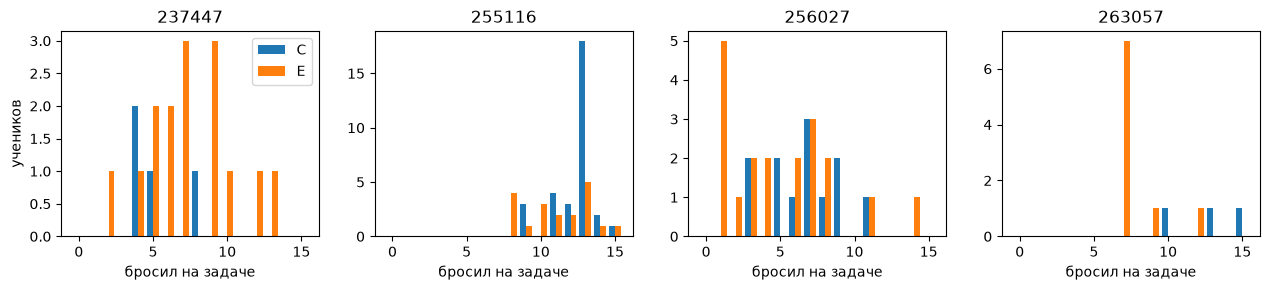

In [9]:
flagged = early[early.k > 0].experiment_id.tolist()
quit = db.run(con, "groups.sql", "quit_position")
fig, axes = plt.subplots(1, len(flagged), figsize=(3.2 * len(flagged), 3), sharey=False)
for ax, eid in zip(axes, flagged):
    d = quit[(quit.experiment_id == eid) & (quit.problem_count <= 15)]
    t = d.pivot_table(index="problem_count", columns="grp", values="n", fill_value=0).reindex(range(16), fill_value=0)
    ax.bar(t.index - 0.2, t.get("C", 0), width=0.4, label="C")
    ax.bar(t.index + 0.2, t.get("E", 0), width=0.4, label="E")
    ax.set_title(str(eid))
    ax.set_xlabel("бросил на задаче")
axes[0].set_ylabel("учеников")
axes[0].legend()
plt.tight_layout()

Кроме 263057 рано бросившие без пары есть ещё в трёх экспериментах:
- 237447: один ученик в E бросил на 2-й задаче, в C всего 5 бросивших. Это шум.
- 255116: в E 4 бросили на 8-й задаче, в C ни одного, но на 9-й наоборот 3 против 1. До 9-й включительно 5 против 3,
  p = 0,13. Условие там увидели все. Похоже на шум.
- 256027: 6 бросивших в E раньше 3-й задачи (5 на первой), в C ни одного, p = 0,031. Это похоже на 263057 в миниатюре,
  и флаг это подтверждает: в C все 76 не увидевших условие завершили задание, а в E 5 не увидевших бросили на 1-й
  задаче. Возможно, в C такие ученики тоже потеряны (предположение). С учётом того, что порог выбран по данным и
  проверок 22, доказательством это не считаю.

In [10]:
db.run(con, "groups.sql", "not_experienced_256027")

,grp,complete,n,min_problems
0,C,1,76,2
1,E,0,5,1
2,E,1,76,2


## Баланс ковариат

Ковариаты из второй статьи: пять числовых, флаг наличия каждой из них (`_valid`), пол и штат. Пол и штат кодирую
индикаторами категорий, штат - только те, у которых в эксперименте не меньше 5% учеников. SMD числовой ковариаты
считается по ученикам, у которых она есть.

Обычный порог |SMD| > 0,1 на маленьких группах срабатывает от шума: при 70 учениках в группе стандартная ошибка
SMD около 0,17. Поэтому для каждого эксперимента дополнительно считаю перестановочный p-value для максимального |SMD|
по всем ковариатам (1000 перестановок меток групп). Он показывает, больше ли перекос, чем даёт случайное деление.

In [11]:
NUMERIC = ["prior_pct_correct", "prior_pct_completion", "z_mastery_speed", "prior_hw_pct_completion", "z_hw_mastery_speed"]


def design(d: pd.DataFrame) -> pd.DataFrame:
    x = d[NUMERIC].copy()
    for c in NUMERIC:
        x[c + "_valid"] = d[c].notna().astype(float)
    for g in ["Female", "Male", "Unknown"]:
        x["gender_" + g] = (d.gender == g).astype(float)
    share = d.state_id.value_counts(normalize=True)
    for s in share[share >= 0.05].index:
        x[f"state_{s}"] = (d.state_id == s).astype(float)
    return x


cov = db.run(con, "groups.sql", "covariates")
smd_rows, summary_rows = [], []
for eid, d in cov.groupby("experiment_id"):
    for sample, part in [("all", d), ("experienced", d[d.experienced])]:
        if sample == "experienced" and len(part) == len(d):
            continue
        x = design(part)
        treated = (part.grp == "E").values
        for c in x:
            smd_rows.append({"experiment_id": eid, "sample": sample, "covariate": c,
                             "smd": stats.smd(x.loc[treated, c], x.loc[~treated, c])})
        summary_rows.append({"experiment_id": eid, "sample": sample, "n": len(part),
                             "balance_p": stats.balance_pvalue(x.values, treated, 1000, rng)})

smd_long = pd.DataFrame(smd_rows)
smd_long["abs_smd"] = smd_long.smd.abs()
balance = pd.DataFrame(summary_rows).merge(
    smd_long.groupby(["experiment_id", "sample"]).agg(
        n_covariates=("smd", "size"),
        max_abs_smd=("abs_smd", "max"),
        n_over_01=("abs_smd", lambda s: (s > 0.1).sum()),
    ).reset_index()
)
balance.round(3)

,experiment_id,sample,n,balance_p,n_covariates,max_abs_smd,n_over_01
0,226210,all,1185,0.866,16,0.093,0
1,226210,experienced,762,0.885,16,0.112,6
2,237447,all,692,0.853,16,0.118,4
3,241501,all,381,0.118,17,0.288,5
4,241501,experienced,273,0.547,18,0.255,4
5,241622,all,627,0.686,16,0.145,4
6,243393,all,1797,0.071,16,0.157,2
7,246482,all,457,0.889,17,0.146,1
8,246627,all,514,0.514,16,0.186,5
9,246647,all,538,0.812,17,0.139,2


In [12]:
worst = smd_long.loc[smd_long.groupby(["experiment_id", "sample"]).abs_smd.idxmax()]
worst.groupby("covariate").size().sort_values(ascending=False)

covariate
prior_hw_pct_completion       9
z_hw_mastery_speed            5
prior_pct_correct_valid       4
gender_Male                   3
prior_pct_correct             3
z_mastery_speed               3
gender_Unknown                2
prior_pct_completion_valid    2
state_22                      2
gender_Female                 1
prior_pct_completion          1
state_36                      1
z_mastery_speed_valid         1
dtype: int64

In [13]:
print("всего SMD:", len(smd_long), " из них |SMD| > 0,1:", (smd_long.abs_smd > 0.1).sum())
print("экспериментов-выборок с перестановочным p < 0,05:", (balance.balance_p < 0.05).sum(), "из", len(balance))

всего SMD: 600  из них |SMD| > 0,1: 179
экспериментов-выборок с перестановочным p < 0,05: 0 из 37


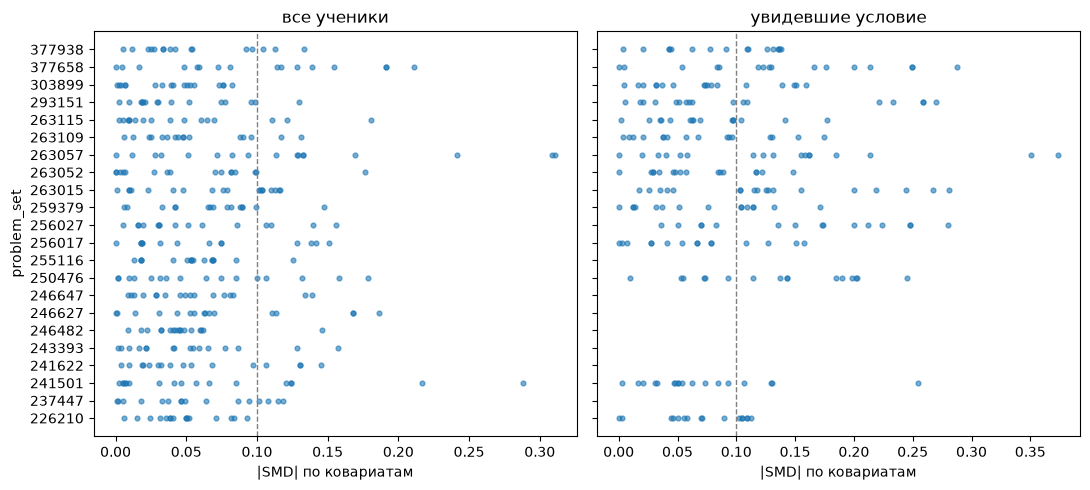

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
order = sorted(smd_long.experiment_id.unique())
for ax, sample in zip(axes, ["all", "experienced"]):
    d = smd_long[smd_long["sample"] == sample]
    y = d.experiment_id.map({e: i for i, e in enumerate(order)})
    ax.scatter(d.abs_smd, y, s=12, alpha=0.6)
    ax.axvline(0.1, color="grey", linestyle="--", linewidth=1)
    ax.set_title("все ученики" if sample == "all" else "увидевшие условие")
    ax.set_xlabel("|SMD| по ковариатам")
axes[0].set_yticks(range(len(order)), order)
axes[0].set_ylabel("problem_set")
plt.tight_layout()

## Проверка видео

`Could See Video` записан после рандомизации, поэтому в основном анализе по нему никого не исключаю. Если вопрос-проверка
одинаков в обеих группах и идёт до условия, доли не видящих видео в C и E должны отличаться только случайно.

In [15]:
video = db.run(con, "quality.sql", "video_check")
rows = []
for eid, d in video.groupby("experiment_id"):
    c, e = d[d.grp == "C"].iloc[0], d[d.grp == "E"].iloc[0]
    p = np.nan
    if c.n_cannot_see + e.n_cannot_see > 0:
        p = stats.two_prop_ztest(e.n_cannot_see, e.n, c.n_cannot_see, c.n)[1]
    rows.append({"experiment_id": eid, "share_cannot_see_c": c.share_cannot_see,
                 "share_cannot_see_e": e.share_cannot_see, "p": p})
video_test = pd.DataFrame(rows)
video_test.round(4)

,experiment_id,share_cannot_see_c,share_cannot_see_e,p
0,250476,0.2383,0.2201,0.6635
1,256017,0.1508,0.1408,0.7757
2,256027,0.1818,0.1353,0.2434
3,259379,0.1506,0.2248,0.0349
4,263015,0.1278,0.1802,0.0535
5,263052,0.0000,0.0000,NaN
6,263109,0.2078,0.2183,0.7917
7,263115,0.2973,0.2448,0.1047
8,293151,0.3606,0.3344,0.3307


In [16]:
tested = video_test.p.dropna()
print("тестов:", len(tested), " p < 0,05:", (tested < 0.05).sum())
print("вероятность хотя бы одного p < 0,05 случайно:", round(1 - 0.95 ** len(tested), 3))
print("минимальный p после поправки BH:", round(false_discovery_control(tested).min(), 3))

тестов: 8  p < 0,05: 1
вероятность хотя бы одного p < 0,05 случайно: 0.337
минимальный p после поправки BH: 0.214


Проверка видео была в 9 экспериментах, тест возможен в 8 (в 263052 видео видят все). Из них одна проверка с p = 0,035
(259379), в 263015 p = 0,054. При восьми тестах хотя бы одно p < 0,05 случайно появляется с вероятностью около 34%,
после поправки BH минимальный p около 0,21. Поэтому разница в 259379 - повод для проверки устойчивости, а не
доказательство проблемы. Исключение не видящих видео, как у авторов, оставляю только для проверки устойчивости на
этапе 3: если вопрос-проверка хоть как-то зависит от группы, такой фильтр ломает сравнимость.

## Насколько триггерный анализ сужает интервал

Доверительный интервал Вальда для разницы долей завершивших на всей выборке и среди увидевших условие. Эффекты на этих
выборках разные: триггерный - эффект для тех, кого условие коснулось. Чтобы сравнить точность на одной шкале, умножаю
ширину триггерного интервала на долю увидевших условие: если на остальных учеников условие не влияет, эффект на всей
выборке равен триггерному, умноженному на эту долю.

In [17]:
comp = db.run(con, "groups.sql", "completion_by_sample")
wide = comp.pivot_table(index=["experiment_id", "sample"], columns="grp", values=["n", "n_done"]).reset_index()
wide.columns = ["experiment_id", "sample", "n_c", "n_e", "done_c", "done_e"]


def width(r):
    lo, hi = stats.diff_ci(r.done_e, r.n_e, r.done_c, r.n_c)
    return hi - lo


wide["ci_width"] = wide.apply(width, axis=1)
ci = wide.pivot(index="experiment_id", columns="sample", values="ci_width").rename(
    columns={"all": "width_all", "experienced": "width_trig"})
ci = ci.join(groups.set_index("experiment_id")[["n_exp_c", "n_exp_e", "n_c", "n_e", "all_experienced", "trigger_p"]])
ci["trigger_share"] = (ci.n_exp_c + ci.n_exp_e) / (ci.n_c + ci.n_e)
ci = ci[~ci.all_experienced & (ci.trigger_p >= 0.05)]
ci["ratio_raw"] = ci.width_trig / ci.width_all
ci["ratio_diluted"] = ci.width_trig * ci.trigger_share / ci.width_all
ci[["trigger_share", "width_all", "width_trig", "ratio_raw", "ratio_diluted"]].round(3)

,trigger_share,width_all,width_trig,ratio_raw,ratio_diluted
experiment_id,,,,,
226210,0.643,0.108,0.138,1.280,0.823
241501,0.717,0.134,0.155,1.155,0.828
250476,0.493,0.111,0.203,1.831,0.902
256017,0.621,0.133,0.183,1.375,0.855
256027,0.531,0.125,0.211,1.680,0.893
259379,0.761,0.176,0.202,1.148,0.873
263015,0.384,0.097,0.191,1.968,0.755
263052,0.730,0.166,0.194,1.166,0.852
263109,0.731,0.106,0.125,1.178,0.861


In [18]:
ci[["ratio_raw", "ratio_diluted"]].median().round(3)

ratio_raw        1.328
ratio_diluted    0.858
dtype: float64

## Итог: на какой выборке анализирую каждый эксперимент

In [19]:
plan = groups[["experiment_id", "n_c", "n_e", "srm_p", "all_experienced", "trigger_p", "has_video_check"]].merge(
    balance[balance["sample"] == "all"][["experiment_id", "max_abs_smd", "balance_p"]], on="experiment_id")


def triggered(r):
    if r.all_experienced:
        return "не нужен: условие увидели все"
    if r.trigger_p < 0.05:
        return "нет: триггер несимметричен"
    return "да"


plan["triggered_analysis"] = plan.apply(triggered, axis=1)
plan["video_robustness"] = np.where(plan.has_video_check, "да", "")
plan["excluded_by_srm"] = plan.srm_p < 0.001
plan.round(3)

,experiment_id,n_c,n_e,srm_p,all_experienced,trigger_p,has_video_check,max_abs_smd,balance_p,triggered_analysis,video_robustness,excluded_by_srm
0,226210,607,578,0.400,False,0.418,False,0.093,0.866,да,,False
1,237447,329,363,0.196,True,NaN,False,0.118,0.853,не нужен: условие увидели все,,False
2,241501,188,193,0.798,False,0.454,False,0.288,0.118,да,,False
3,241622,338,289,0.050,True,NaN,False,0.145,0.686,не нужен: условие увидели все,,False
4,243393,910,887,0.587,True,NaN,False,0.157,0.071,не нужен: условие увидели все,,False
5,246482,225,232,0.743,True,NaN,False,0.146,0.889,не нужен: условие увидели все,,False
6,246627,279,235,0.052,True,NaN,False,0.186,0.514,не нужен: условие увидели все,,False
7,246647,264,274,0.666,True,NaN,False,0.139,0.812,не нужен: условие увидели все,,False
8,250476,193,209,0.425,False,0.990,True,0.179,0.695,да,да,False
9,255116,258,276,0.436,True,NaN,False,0.125,0.942,не нужен: условие увидели все,,False


- SRM не нашёл ни одного эксперимента с перекосом: минимальный p равен 0,050 (241622), следующий 0,052 (246627).
  По SRM никого не исключаю. Деление 50/50 - допущение, в статьях оно не указано.
- Триггер. В 8 экспериментах условие увидели все, там триггерная выборка совпадает с полной. В 13 экспериментах доли
  увидевших условие в C и E не различаются (все p > 0,15), там триггерный анализ делаю как вторичный. В 263057 триггер
  несимметричен (p = 0,006), триггерного анализа там нет. Полная выборка в 263057 тоже под вопросом: 7 бросивших
  на 7-й задаче есть только в группе E.
- Баланс ковариат. Из 600 SMD 179 больше 0,1, но перестановочная проверка ни в одной из 37 выборок не дала p < 0,05.
  Перекосы не больше, чем при случайном делении. Самые большие |SMD| в маленьких экспериментах: 0,31 в 263057 на
  136 учениках.
- Проверка видео. Доли не видящих видео в C и E различаются в 259379 (p = 0,035), в 263015 p = 0,054, в остальных
  p > 0,1. Одно срабатывание из восьми укладывается в случайность. В основном анализе по видео никого не исключаю,
  выборка без не видящих видео - только проверка устойчивости в 9 экспериментах с видео.
- Триггерный анализ и интервал. Среди увидевших условие интервал для разницы долей в среднем (медиана) в 1,33 раза
  шире, чем на всей выборке: учеников меньше, а доля завершивших у них ближе к 50%. Но если пересчитать его на эффект
  для всех учеников (умножить на долю увидевших), он в 0,86 раза уже. Это примерно как если бы учеников было
  в 1,36 раза больше. Пересчёт верен, только если на не увидевших условие оно не влияет.
- Исключённых по SRM и балансу экспериментов нет. 263057 исключаю из таблицы решений: группы несравнимы и на полной
  выборке, и среди увидевших условие, а фильтр по 10-й задаче отбирает по следствию воздействия. Его оценки по обеим
  выборкам - только справочно.
- Рано бросившие без пары, кроме 263057, есть в 256027 (6 в E, p = 0,031 при пороге, выбранном по данным). Оставляю
  его в таблице решений, но проверяю устойчивость: добавляю в C 6 бросивших, которых там могло не хватать.

## План анализа, зафиксирован до расчёта эффектов

Этот раздел записан и закоммичен до того, как я посчитал хоть один эффект, и после расчёта не меняется.

- Основная выборка - все ученики в файле. Основная метрика - доля завершивших задание, эффект - разница долей E - C.
  Тест - двусторонний z-тест для долей, интервал - перцентильный бутстреп 95% (10 000 повторов, сид 42).
- Множественные сравнения - поправка BH по 21 эксперименту (без 263057) на уровне 0,05, Bonferroni справочно.
- Правило решений:
  - выкатывать - значим после BH и эффект больше нуля;
  - не выкатывать - значим после BH и эффект меньше нуля, или незначим и верхняя граница интервала ниже +3 п.п.
    (заметное улучшение исключено);
  - мало данных - незначим и интервал содержит +3 п.п.
- Вторичная выборка - триггерный анализ среди увидевших условие, только в 13 экспериментах с симметричным триггером.
- Проверки устойчивости: триггерный анализ, выборка без не видящих видео в 9 экспериментах с видео, 256027 с 6
  добавленными бросившими в C. Решение они не меняют, только дают оговорки. Исключение - 256027: если с добавленными
  бросившими решение другое, пишу «мало данных».
- Вторичная метрика - разница средних log10(ProblemCount) среди завершивших, бутстреп 95%. В решение не входит: если
  условие меняет, кто завершает, сравнение завершивших смещено.
- 263057 в таблицу решений не входит, его оценки по обеим выборкам - справочно.